# Project 5: Sentiment Analysis of Movie Reviews

This notebook builds an end-to-end **natural language processing** workflow that classifies movie reviews as positive or negative and shows which words drive each prediction.

**Workflow:** data loading, text cleaning, exploratory analysis, TF-IDF vectorisation, comparison of three classifiers, evaluation with error analysis, word-level interpretation, model saving and prediction on new reviews.

## 1. Project Introduction

Companies, studios and platforms receive far more written feedback than anyone can read. Sentiment analysis turns free text into a signal that can be counted, tracked and acted on. The IMDB Movie Reviews dataset contains 50,000 reviews that are labelled `positive` or `negative`, with the two classes in equal numbers.

## 2. Problem Statement

Given the text of a movie review, predict whether its sentiment is positive or negative.

- **Type:** supervised learning, binary text classification
- **Models compared:** Logistic Regression, Multinomial Naive Bayes and a calibrated Linear SVM, all on TF-IDF features of words and word pairs
- **Metrics:** accuracy, precision, recall, F1 and ROC AUC. Model selection uses stratified 5-fold cross-validation ROC AUC on the training set only. The test set is used once for the final evaluation.

In [29]:
import json
import tempfile
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

from features import (
    POSITIVE_LABEL,
    TARGET_COLUMN,
    TEXT_COLUMN,
    TOKEN_PATTERN,
    clean_text,
)

# ---- Settings ----
RANDOM_STATE = 42
MAX_ROWS = None  # e.g. 10000 for a quick run; None uses the full dataset
LOCAL_DATA_FILE = Path("imdb_reviews.csv")
DATA_URLS = [
    "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv",
]
warnings.filterwarnings("ignore", category=FutureWarning)


## 3. Dataset Loading

The dataset is read directly from a public GitHub raw URL. No manual download is needed. The file is about 60 MB, so the first load can take a short while.

In [30]:
COLUMN_ALIASES = {
    "review": ["review", "text", "content", "comment"],
    "sentiment": ["sentiment", "label", "class", "target"],
}
LABEL_MAP = {
    "1": "positive", "0": "negative", "1.0": "positive", "0.0": "negative",
    "pos": "positive", "neg": "negative", "positive": "positive", "negative": "negative",
}


def standardise(frame):
    """Rename columns to review/sentiment and turn labels (0/1, pos/neg) into positive/negative."""
    lowered = {name.lower().strip(): name for name in frame.columns}
    renames = {}
    for target, options in COLUMN_ALIASES.items():
        for option in options:
            if option in lowered:
                renames[lowered[option]] = target
                break
    frame = frame.rename(columns=renames)
    if TARGET_COLUMN in frame.columns:
        frame[TARGET_COLUMN] = frame[TARGET_COLUMN].astype(str).str.lower().str.strip().map(LABEL_MAP)
    return frame


def load_reviews():
    candidates = [Path(LOCAL_DATA_FILE)] + sorted(Path(".").glob("*.csv")) + sorted(Path("data").glob("*.csv"))
    seen = set()
    for path in candidates:
        if path in seen or not path.exists():
            continue
        seen.add(path)
        try:
            frame = standardise(pd.read_csv(path))
        except Exception as error:
            print(f"Skipped {path}: {error}")
            continue
        if {TEXT_COLUMN, TARGET_COLUMN} <= set(frame.columns):
            print(f"Loaded local file: {path}")
            return frame
        print(f"Skipped {path}: columns are {list(frame.columns)}")
    for url in DATA_URLS:
        try:
            frame = standardise(pd.read_csv(url))
            frame.to_csv(LOCAL_DATA_FILE, index=False)  # cache for next runs
            return frame
        except Exception as error:
            print(f"Could not load {url}: {error}")
    raise FileNotFoundError(
        f"No usable CSV found. Working folder: {Path.cwd()}. "
        f"Put the dataset next to the notebook as {LOCAL_DATA_FILE}."
    )


reviews = load_reviews()
print(f"Rows: {reviews.shape[0]:,}  Columns: {reviews.shape[1]}")
print(reviews[TARGET_COLUMN].value_counts(dropna=False).to_dict())
reviews.head()

Loaded local file: imdb_reviews.csv
Rows: 50,000  Columns: 2
{'negative': 25000, 'positive': 25000}


,review,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,negative
1,"""I Am Curious: Yellow"" is a risible and preten...",negative
2,If only to avoid making this type of film in t...,negative
3,This film was probably inspired by Godard's Ma...,negative
4,"Oh, brother...after hearing about this ridicul...",negative


## 4. Data Overview

In [31]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


In [32]:
print(f"Missing values:\n{reviews.isna().sum().to_string()}")
print(f"\nDuplicate reviews: {reviews[TEXT_COLUMN].duplicated().sum()}")
print(f"Labels: {reviews[TARGET_COLUMN].value_counts().to_dict()}")
reviews[TEXT_COLUMN].str.len().describe().round(0).to_frame("characters per review").T

Missing values:
review       0
sentiment    0

Duplicate reviews: 418
Labels: {'negative': 25000, 'positive': 25000}


,count,mean,std,min,25%,50%,75%,max
characters per review,50000.0,1309.0,990.0,32.0,699.0,970.0,1590.0,13704.0


## 5. Data Cleaning

Cleaning steps:

1. Remove rows with a missing review or label.
2. Remove exact duplicate reviews. The same text must not end up in both the training and the test set.
3. Convert the label to 1 (positive) and 0 (negative).
4. Optionally take a stratified subsample (`MAX_ROWS`) for a quicker run.

The text itself is cleaned **inside the model** by `clean_text` from `features.py` (lower-casing, removal of HTML tags such as `<br />`, links and symbols). That way the saved model cleans new reviews in exactly the same way as the training data. Stop words are deliberately **kept**, because words like "not" change the meaning of a review.

In [33]:
rows_initial = len(reviews)
reviews_clean = (
    reviews.dropna(subset=[TEXT_COLUMN, TARGET_COLUMN])
    .drop_duplicates(subset=TEXT_COLUMN)
    .reset_index(drop=True)
)
reviews_clean = reviews_clean[reviews_clean[TARGET_COLUMN].isin([POSITIVE_LABEL, "negative"])].reset_index(drop=True)
reviews_clean["label"] = (reviews_clean[TARGET_COLUMN] == POSITIVE_LABEL).astype(int)


if MAX_ROWS is not None and MAX_ROWS < len(reviews_clean):
    reviews_clean, _ = train_test_split(
        reviews_clean, train_size=MAX_ROWS, stratify=reviews_clean["label"], random_state=RANDOM_STATE
    )
    reviews_clean = reviews_clean.reset_index(drop=True)

assert len(reviews_clean) > 0, "No rows left after cleaning: check the label values in the sentiment column."
print(f"Rows before cleaning: {rows_initial:,}")
print(f"Rows after cleaning:  {len(reviews_clean):,}")
print(f"Positive share: {reviews_clean['label'].mean():.1%}")

Rows before cleaning: 50,000
Rows after cleaning:  49,582
Positive share: 50.2%


## 6. Exploratory Data Analysis

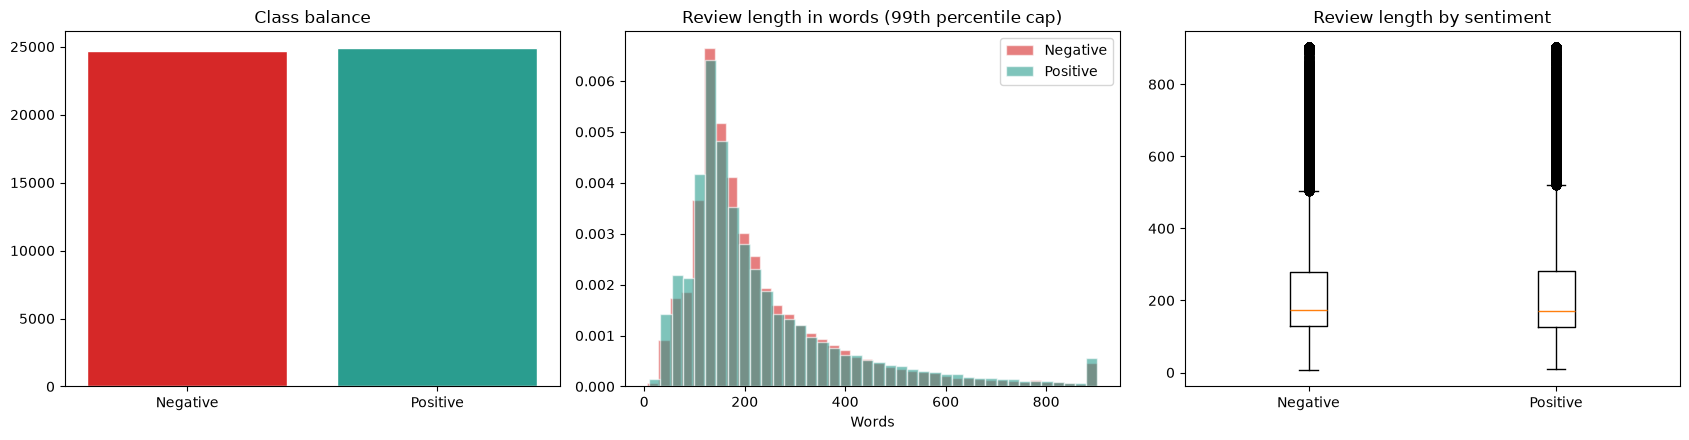

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,24698.0,229.3,164.5,6.0,128.0,174.0,278.0,1522.0
1,24884.0,232.9,177.3,10.0,125.0,172.0,283.0,2473.0


In [34]:
reviews_clean["word_count"] = reviews_clean[TEXT_COLUMN].map(lambda text: len(clean_text(text).split()))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
counts = reviews_clean["label"].value_counts().reindex([0, 1], fill_value=0).sort_index()
axes[0].bar(["Negative", "Positive"], counts.values, color=["#d62828", "#2a9d8f"], edgecolor="white")
axes[0].set_title("Class balance")
word_counts = pd.to_numeric(reviews_clean["word_count"], errors="coerce").dropna()
upper_limit = float(word_counts.quantile(0.99)) if not word_counts.empty else 0.0
for label, color, name in [(0, "#d62828", "Negative"), (1, "#2a9d8f", "Positive")]:
    axes[1].hist(
        reviews_clean.loc[reviews_clean["label"] == label, "word_count"].clip(upper=upper_limit),
        bins=40, alpha=0.6, color=color, label=name, edgecolor="white", density=True,
    )
axes[1].set_title("Review length in words (99th percentile cap)")
axes[1].set_xlabel("Words")
axes[1].legend()
axes[2].boxplot(
    [reviews_clean.loc[reviews_clean["label"] == label, "word_count"].clip(upper=upper_limit) for label in (0, 1)]
)
axes[2].set_xticks([1, 2])
axes[2].set_xticklabels(["Negative", "Positive"])
axes[2].set_title("Review length by sentiment")
plt.tight_layout()
plt.show()
reviews_clean.groupby("label")["word_count"].describe().round(1)

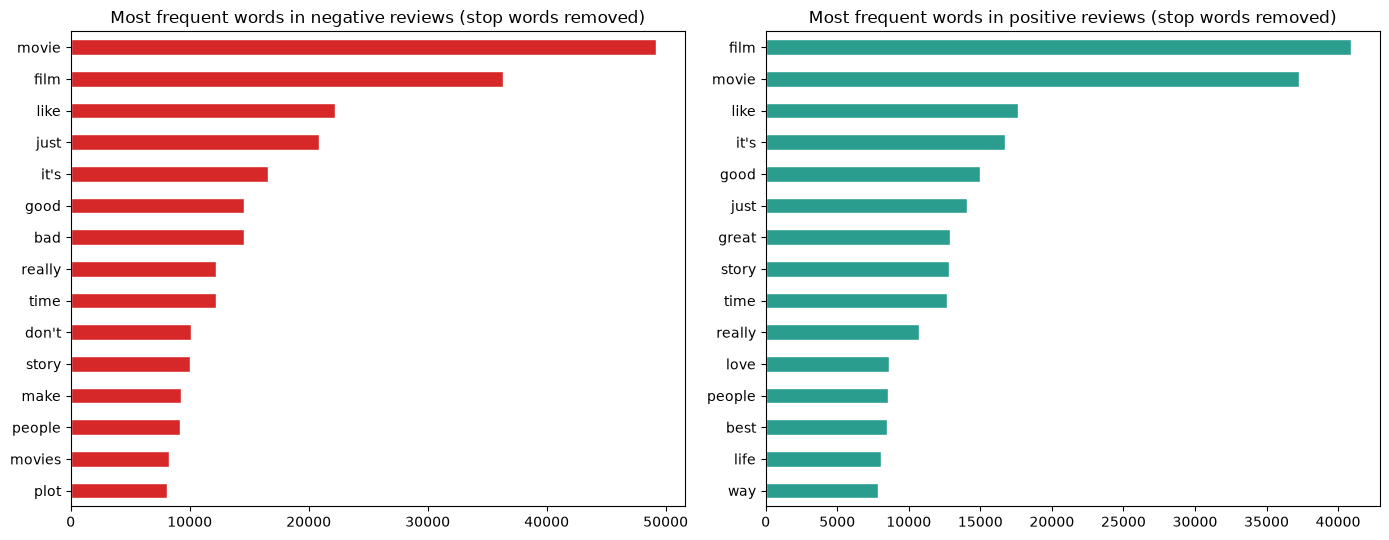

In [35]:
def top_words(texts, count=15):
    vectorizer = CountVectorizer(preprocessor=clean_text, token_pattern=TOKEN_PATTERN, stop_words="english", min_df=2)
    matrix = vectorizer.fit_transform(texts)
    totals = np.asarray(matrix.sum(axis=0)).ravel()
    order = np.argsort(totals)[::-1][:count]
    return pd.Series(totals[order], index=vectorizer.get_feature_names_out()[order])


fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for axis, (label, color, name) in zip(axes, [(0, "#d62828", "negative"), (1, "#2a9d8f", "positive")]):
    label_reviews = reviews_clean.loc[reviews_clean["label"] == label, TEXT_COLUMN].dropna().astype(str)
    if label_reviews.empty:
        words = pd.Series(dtype="float64")
    else:
        try:
            words = top_words(label_reviews)
        except ValueError:
            vectorizer = CountVectorizer(preprocessor=clean_text, token_pattern=TOKEN_PATTERN, min_df=1)
            matrix = vectorizer.fit_transform(label_reviews)
            totals = np.asarray(matrix.sum(axis=0)).ravel()
            order = np.argsort(totals)[::-1][:15]
            words = pd.Series(totals[order], index=vectorizer.get_feature_names_out()[order])
    words.sort_values().plot(kind="barh", ax=axis, color=color, edgecolor="white")
    axis.set_title(f"Most frequent words in {name} reviews (stop words removed)")
plt.tight_layout()
plt.show()

In [36]:
sample_rows = reviews_clean.sample(3, random_state=RANDOM_STATE)
for _, row in sample_rows.iterrows():
    print(f"[{row[TARGET_COLUMN]}] {row[TEXT_COLUMN][:300]}...\n")

[negative] The producers of this film should be sued for the misrepresentation of copyrighted materials, namely the Advanced Dungeons & Dragons Players' Handbook. Fear and ignorance breed the sort of mindless propaganda that inspire garbage like this film. If any of you have any doubts about the innocence of D...

[positive] The plot starts out interesting, however, towards the end too many die in too short a time, turning the thriller-mystery aspect of the story into a slaughter.<br /><br />The only true highlights were Adam Beach and Jürgen Prochnow, who were once again their excellent selves. Nice try with an inappro...

[positive] I saw this movie on television as SCREAMERS and loved it. I heard an interesting story about this film. When Roger Corman released it to drive-ins in the summer of 1981, his trailer department sent out an advance trailer which was not actually footage from the film. It was allegedly footage of a nak...



## 7. Data Preprocessing

The data is split into training and test sets **before** any vocabulary or weighting is learned. The split is stratified on the label. The TF-IDF vectoriser is a step of the modelling `Pipeline`, so its vocabulary and inverse document frequencies are learned from the training folds only and reused unchanged at prediction time.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    reviews_clean[TEXT_COLUMN],
    reviews_clean["label"],
    test_size=0.2,
    stratify=reviews_clean["label"],
    random_state=RANDOM_STATE,
)
print(f"Training rows: {len(X_train):,}  Test rows: {len(X_test):,}")
print(f"Positive share  train: {y_train.mean():.3f}  test: {y_test.mean():.3f}")
print(f"Reviews that appear in both sets: {len(set(X_train) & set(X_test))}")

cache_directory = tempfile.mkdtemp()


def build_pipeline(estimator, memory=None):
    vectorizer = TfidfVectorizer(
        preprocessor=clean_text,
        token_pattern=TOKEN_PATTERN,
        ngram_range=(1, 2),
        min_df=5,
        max_df=0.9,
        max_features=100000,
        sublinear_tf=True,
    )
    return Pipeline([("tfidf", vectorizer), ("model", estimator)], memory=memory)

Training rows: 39,665  Test rows: 9,917
Positive share  train: 0.502  test: 0.502
Reviews that appear in both sets: 0


## 8. Feature Engineering

Text becomes numbers with **TF-IDF** (term frequency times inverse document frequency):

- Single words and **word pairs** (`ngram_range=(1, 2)`) are used, so phrases such as "not good" or "well worth" keep their meaning.
- Very rare terms (`min_df=5`) and terms in more than 90% of reviews (`max_df=0.9`) are dropped, and the vocabulary is capped at 100,000 terms.
- `sublinear_tf` dampens the effect of a word repeated many times in one long review.

The fitted vocabulary is inspected after training in the interpretation section.

In [38]:
preview_vectorizer = build_pipeline(LogisticRegression()).named_steps["tfidf"].fit(X_train)
vocabulary_size = len(preview_vectorizer.vocabulary_)
preview_matrix = preview_vectorizer.transform(X_train.head(500))
density = preview_matrix.nnz / (preview_matrix.shape[0] * preview_matrix.shape[1])
print(f"Vocabulary size learned from the training set: {vocabulary_size:,} terms")
print(f"Share of non-zero cells in a TF-IDF matrix: {density:.3%}")

Vocabulary size learned from the training set: 100,000 terms
Share of non-zero cells in a TF-IDF matrix: 0.237%


## 9. Model Training

Three linear models that suit high-dimensional sparse text are compared with the same TF-IDF step. Each is scored with stratified 5-fold cross-validation on the training set and then fitted on the full training set. A shared cache stores the fitted vectoriser for each fold, so it is not recomputed for every model.

In [ ]:
candidate_models = {
    "Logistic Regression": LogisticRegression(C=4.0, max_iter=2000, random_state=RANDOM_STATE),
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.3),
    "Linear SVM (calibrated)": CalibratedClassifierCV(LinearSVC(C=0.5, random_state=RANDOM_STATE), cv=3),
}

cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"}
cross_validation_rows = []
fitted_pipelines = {}

for model_name, estimator in candidate_models.items():
    pipeline = build_pipeline(estimator, memory=cache_directory)
    scores = cross_validate(pipeline, X_train, y_train, cv=cross_validation, scoring=scoring, n_jobs=-1)
    pipeline.fit(X_train, y_train)
    pipeline.set_params(memory=None)
    fitted_pipelines[model_name] = pipeline
    print(f"Trained {model_name}")

candidate_models = {
    "Logistic Regression": LogisticRegression(C=4.0, max_iter=2000, random_state=RANDOM_STATE),
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.3),
    "Linear SVM (calibrated)": CalibratedClassifierCV(
        LinearSVC(C=0.5, random_state=RANDOM_STATE), cv=3
    ),
}

cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"}
cross_validation_rows = []
fitted_pipelines = {}

for model_name, estimator in candidate_models.items():
    pipeline = build_pipeline(estimator, memory=cache_directory)
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cross_validation, scoring=scoring, n_jobs=-1
    )

    cross_validation_rows.append({
        "model": model_name,
        "cv_roc_auc": scores["test_roc_auc"].mean(),
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_f1": scores["test_f1"].mean(),
    })

    pipeline.fit(X_train, y_train)
    pipeline.set_params(memory=None)
    fitted_pipelines[model_name] = pipeline
    print(f"Trained {model_name}")

cross_validation_table = pd.DataFrame(cross_validation_rows).set_index("model")
cross_validation_table.round(4)
cross_validation_table.round(4)

Trained Logistic Regression


## 10. Model Comparison

All models are scored on the untouched test set with the default decision threshold of 0.5. The classes are balanced, so accuracy is a meaningful headline metric.

In [ ]:
def classification_scores(model_name, fitted_pipeline, texts, target_values):
    probabilities = fitted_pipeline.predict_proba(texts)[:, 1]
    predicted_labels = (probabilities >= 0.5).astype(int)
    return {
        "model": model_name,
        "accuracy": accuracy_score(target_values, predicted_labels),
        "precision": precision_score(target_values, predicted_labels),
        "recall": recall_score(target_values, predicted_labels),
        "f1": f1_score(target_values, predicted_labels),
        "roc_auc": roc_auc_score(target_values, probabilities),
    }


test_table = pd.DataFrame(
    [classification_scores(name, pipeline, X_test, y_test) for name, pipeline in fitted_pipelines.items()]
).set_index("model")
test_table.round(4)

In [ ]:
ax = test_table[["accuracy", "precision", "recall", "f1", "roc_auc"]].plot(kind="bar", figsize=(12, 5), edgecolor="white")
ax.set_title("Test-set performance by model")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 11. Model Evaluation

The best model is selected by cross-validated ROC AUC and then examined in detail: classification report, confusion matrix, ROC curves, accuracy by review length and the most confident mistakes.

In [ ]:
best_model_name = cross_validation_table["cv_roc_auc"].idxmax()
best_pipeline = fitted_pipelines[best_model_name]
best_probabilities = best_pipeline.predict_proba(X_test)[:, 1]
best_predictions = (best_probabilities >= 0.5).astype(int)
print(f"Selected model: {best_model_name}\n")
print(classification_report(y_test, best_predictions, target_names=["Negative", "Positive"]))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, display_labels=["Negative", "Positive"], cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title(f"Confusion matrix: {best_model_name}")
axes[0].grid(False)
for model_name, pipeline in fitted_pipelines.items():
    RocCurveDisplay.from_estimator(pipeline, X_test, y_test, ax=axes[1], name=model_name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set_title("ROC curves on the test set")
plt.tight_layout()
plt.show()

In [ ]:
test_frame = pd.DataFrame(
    {
        "text": X_test.values,
        "actual": y_test.values,
        "predicted": best_predictions,
        "positive_probability": best_probabilities,
        "word_count": [len(clean_text(text).split()) for text in X_test],
    }
)
test_frame["correct"] = test_frame["actual"] == test_frame["predicted"]
test_frame["length_group"] = pd.qcut(
    test_frame["word_count"].rank(method="first"), q=4, labels=["shortest 25%", "short-medium", "medium-long", "longest 25%"]
)
accuracy_by_length = test_frame.groupby("length_group", observed=True)["correct"].agg(["mean", "count"])
print("Accuracy by review length (quartiles of word count):")
print(accuracy_by_length.round(4))

test_frame["confidence_in_wrong_label"] = np.where(
    test_frame["predicted"] == 1, test_frame["positive_probability"], 1 - test_frame["positive_probability"]
)
confident_errors = test_frame[~test_frame["correct"]].sort_values("confidence_in_wrong_label", ascending=False).head(3)
print("\nMost confident mistakes:")
for _, row in confident_errors.iterrows():
    actual = "positive" if row["actual"] == 1 else "negative"
    print(f"- actual {actual}, confidence in the wrong label {row['confidence_in_wrong_label']:.2f}: {row['text'][:250]}...")

### Which words drive the prediction?

The coefficients of the logistic regression model show how each word or word pair moves the prediction: positive weights push towards a positive review and negative weights towards a negative one. These weights are also used by the Streamlit app to highlight the words that influenced a prediction.

In [ ]:
logistic_pipeline = fitted_pipelines["Logistic Regression"]
terms = logistic_pipeline.named_steps["tfidf"].get_feature_names_out()
coefficients = pd.Series(logistic_pipeline.named_steps["model"].coef_[0], index=terms).sort_values()

strongest = pd.concat([coefficients.head(15), coefficients.tail(15)])
colors = ["#d62828" if value < 0 else "#2a9d8f" for value in strongest.values]
strongest.plot(kind="barh", color=colors, figsize=(9, 9))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Strongest terms in the logistic regression model (green: positive, red: negative)")
plt.xlabel("Coefficient")
plt.show()

## 12. Best Model Selection

The model with the highest mean cross-validated ROC AUC on the training data is selected. Choosing with cross-validation instead of the test set keeps the test score an honest estimate of how the model behaves on reviews it has never seen.

In [ ]:
best_test_metrics = classification_scores(best_model_name, best_pipeline, X_test, y_test)
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"Test {metric:<9}: {best_test_metrics[metric]:.4f}")

## 13. Model Saving

The complete pipeline (text cleaning, TF-IDF and classifier) is saved as `model.pkl`. The file `metadata.json` stores the evaluation tables, the confusion matrix, the ROC curve and the term weights used by the Streamlit app.

In [ ]:
def json_default(value):
    return value.item() if hasattr(value, "item") else str(value)


TERMS_PER_SIDE = 300
term_weights = {
    **{term: round(float(weight), 4) for term, weight in coefficients.head(TERMS_PER_SIDE).items()},
    **{term: round(float(weight), 4) for term, weight in coefficients.tail(TERMS_PER_SIDE).items()},
}
display_terms = {
    "negative": {term: round(float(weight), 4) for term, weight in coefficients.head(15).items()},
    "positive": {term: round(float(weight), 4) for term, weight in coefficients.tail(15)[::-1].items()},
}
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, best_probabilities)
curve_step = max(len(false_positive_rate) // 100, 1)

metadata = {
    "project": "Sentiment Analysis of Movie Reviews",
    "best_model": best_model_name,
    "test_metrics": best_test_metrics,
    "model_comparison": cross_validation_table.join(test_table, rsuffix="_test").reset_index().to_dict(orient="records"),
    "confusion_matrix": confusion_matrix(y_test, best_predictions).tolist(),
    "roc_curve": {
        "false_positive_rate": false_positive_rate[::curve_step].tolist(),
        "true_positive_rate": true_positive_rate[::curve_step].tolist(),
    },
    "term_weights": term_weights,
    "display_terms": display_terms,
    "vocabulary_size": int(vocabulary_size),
    "median_review_words": float(reviews_clean["word_count"].median()),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
}

best_pipeline.set_params(memory=None)
joblib.dump(best_pipeline, "model.pkl")
with open("metadata.json", "w", encoding="utf-8") as metadata_file:
    json.dump(metadata, metadata_file, indent=2, default=json_default)
print("Saved model.pkl and metadata.json")

## 14. Prediction on New Data

The saved model is loaded from disk and applied to new reviews written by hand. The raw text is passed in directly because cleaning and vectorisation are part of the saved pipeline.

In [ ]:
loaded_model = joblib.load("model.pkl")

new_reviews = [
    "An absolute joy from start to finish. The acting was superb and the story kept me hooked.",
    "I wanted to like this film, but the plot was dull, the dialogue was awful and it dragged on forever.",
    "The special effects were impressive, however the script was weak and I was not impressed overall.",
    "<br />Not good. Not good at all.<br />",
]

new_probabilities = loaded_model.predict_proba(new_reviews)[:, 1]
predictions_table = pd.DataFrame(
    {
        "review": [text[:70] + ("..." if len(text) > 70 else "") for text in new_reviews],
        "positive_probability": new_probabilities.round(3),
        "prediction": np.where(new_probabilities >= 0.5, "Positive", "Negative"),
    }
)
consistency_check = bool(np.allclose(loaded_model.predict_proba(X_test.head(50)), best_pipeline.predict_proba(X_test.head(50))))
print(f"Loaded model matches the in-memory model: {consistency_check}")
predictions_table

## 15. Final Conclusion

In [ ]:
strongest_positive = ", ".join(display_terms["positive"].keys())
strongest_negative = ", ".join(display_terms["negative"].keys())
print(f"Best model by cross-validated ROC AUC: {best_model_name}")
print(
    f"Test accuracy {best_test_metrics['accuracy']:.3f} | precision {best_test_metrics['precision']:.3f} | "
    f"recall {best_test_metrics['recall']:.3f} | F1 {best_test_metrics['f1']:.3f} | ROC AUC {best_test_metrics['roc_auc']:.3f}"
)
print(f"Strongest positive terms (logistic regression): {strongest_positive}")
print(f"Strongest negative terms (logistic regression): {strongest_negative}")
print()
print("Model ranking on the test set (ROC AUC):")
print(test_table["roc_auc"].sort_values(ascending=False).round(4).to_string())

**Summary of the approach**

- Duplicates were removed before the split, and the vocabulary was learned from training data only, so the test score is not inflated by leakage.
- The model file contains text cleaning, TF-IDF and the classifier, so the app scores new text exactly as the notebook does.
- Word-level weights make the predictions explainable, which helps to spot when a model relies on odd or misleading words.

**Limitations and next steps**

- Bag-of-words models ignore word order beyond word pairs, so sarcasm, mixed reviews ("great effects, terrible script") and long-range negation are hard cases. The confident mistakes above show typical failures.
- The model learned from movie reviews written in English. It may not transfer to other domains such as product reviews or social media.
- Possible improvements: hyperparameter search, character n-grams, pre-trained word embeddings, and fine-tuned transformer models such as DistilBERT, which usually handle context and negation better at a much higher computational cost.